In [20]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import ipywidgets as widgets
from IPython.display import display

In [4]:
PROJECT_DIR = Path.cwd().parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Processed data:", PROCESSED_DIR)

Project: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach
Processed data: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed


In [7]:
#loading the combined data set
ground = pd.read_csv(PROCESSED_DIR / "All_Stations_Ground_Cleaned.csv",parse_dates=["Date"])
display(ground.head())

print("Stations:", ground["Station"].unique())
print("Total records:", len(ground))

,Date,Station,Original_Value,Rainfall_mm,QC_Flag
0,1981-01-01,Badulla,12.4,12.4,Valid
1,1981-01-02,Badulla,16.4,16.4,Valid
2,1981-01-03,Badulla,37.2,37.2,Valid
3,1981-01-04,Badulla,6.4,6.4,Valid
4,1981-01-05,Badulla,.0T,0.0,Trace


Stations: <StringArray>
['Badulla', 'Colombo', 'Galle', 'Kandy', 'Nuwaraeliya', 'Puttalam']
Length: 6, dtype: str
Total records: 43830


#Resuable plotting function
def plot_ground_rainfall(station, start_date, end_date):
    data = ground[
        (ground["Station"] == station) &
        (ground["Date"] >= start_date) &
        (ground["Date"] <= end_date)
    ].copy()

    data = data.sort_values("Date")
    plt.figure(figsize=(14, 5))
    plt.scatter(data["Date"],data["Rainfall_mm"],color="red")
    plt.plot(data["Date"],data["Rainfall_mm"],color="royalblue",linewidth=1)
    plt.title(f"{station}: Daily Ground Rainfall")
    plt.xlabel("Date")
    plt.ylabel("Rainfall (mm/day)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [10]:
def plot_ground_rainfall(station, start_date, end_date):

    # Convert widget dates to pandas timestamps
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    # Check date selection
    if start_date > end_date:
        print("Error: Start date must be before end date.")
        return

    # Select station and date range
    data = ground[
        (ground["Station"] == station) &
        (ground["Date"] >= start_date) &
        (ground["Date"] <= end_date)
    ].copy()

    data = data.sort_values("Date")

    if data.empty:
        print("No rainfall data found for this selection.")
        return

    # Plot
    plt.figure(figsize=(14, 5))
    plt.scatter(data["Date"],data["Rainfall_mm"],color="red")
    plt.plot(data["Date"],data["Rainfall_mm"],color="royalblue",linewidth=1)
    plt.title(f"{station}: Daily Ground Rainfall")
    plt.xlabel("Date")
    plt.ylabel("Rainfall (mm/day)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

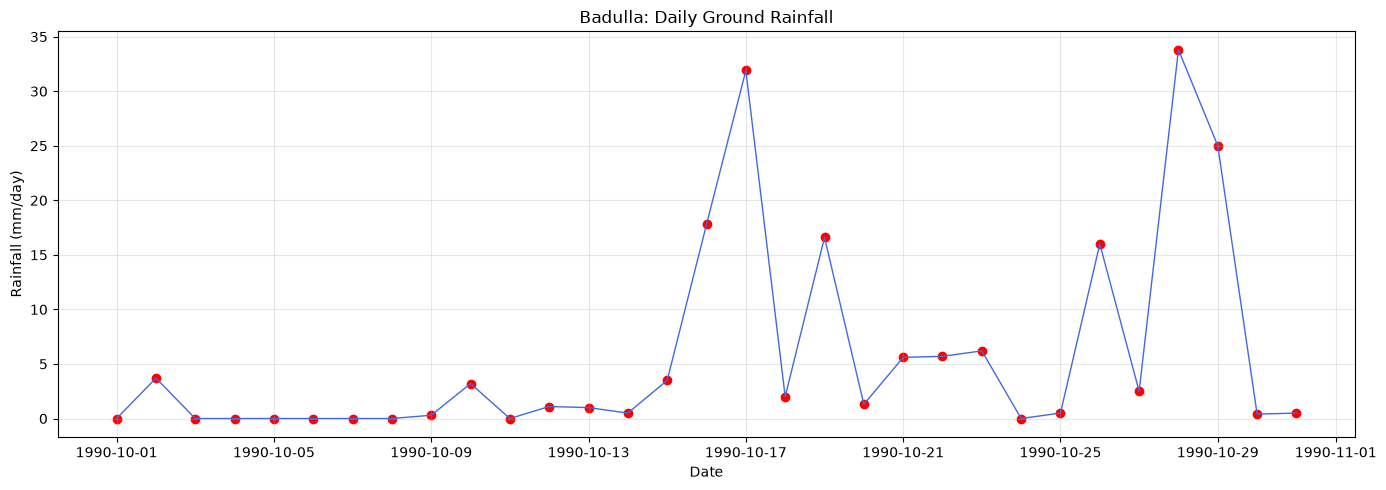

In [12]:
plot_ground_rainfall("Badulla","1990-10-01","1990-10-31")

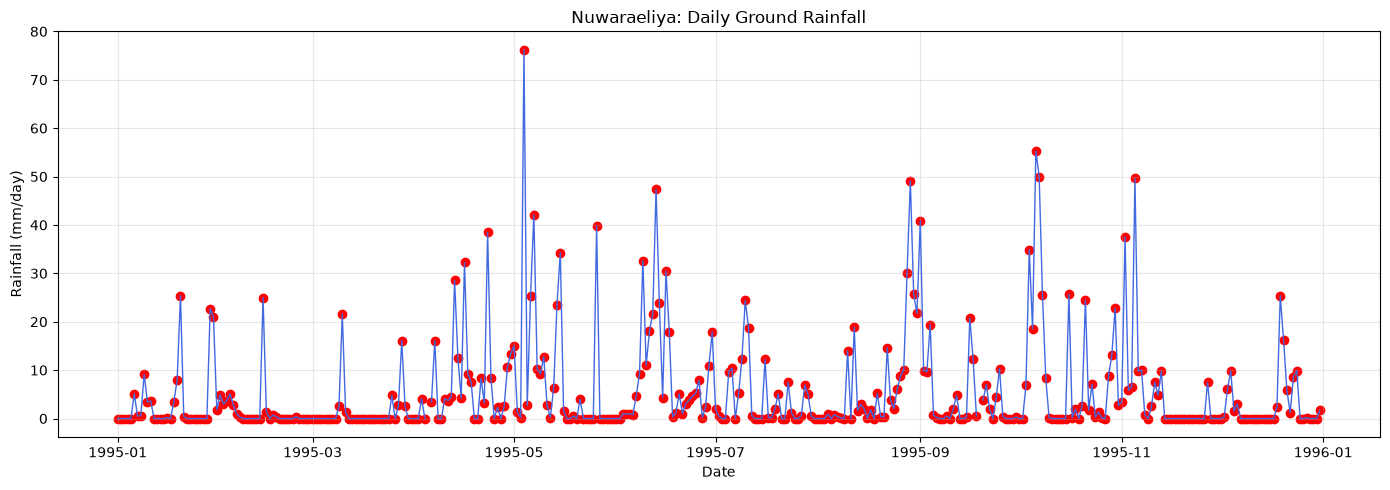

In [14]:
plot_ground_rainfall("Nuwaraeliya","1995-01-01","1995-12-31")

In [16]:
#addining interactive menue 
#Create the controls
station_menu = widgets.Dropdown(
    options=sorted(ground["Station"].unique()),
    value="Badulla",
    description="Station:"
)

start_date = widgets.DatePicker(
    description="From:",
    value=pd.Timestamp("1990-01-01").date()
)

end_date = widgets.DatePicker(
    description="To:",
    value=pd.Timestamp("1990-12-31").date()
)

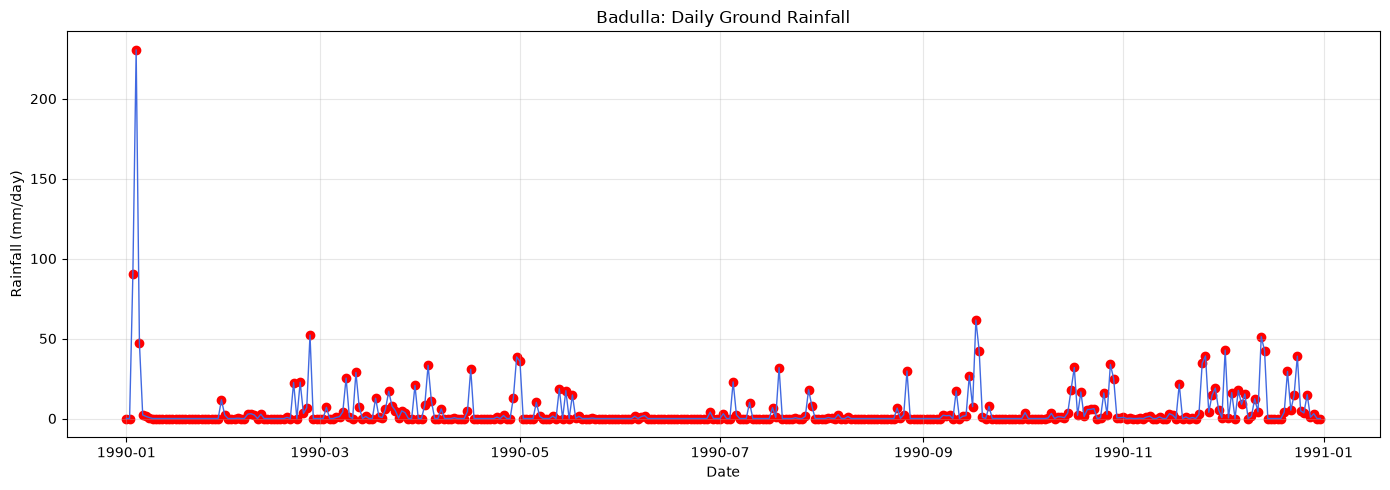

In [18]:
#connect to the plotting function
interactive_plot = widgets.interactive_output(
    plot_ground_rainfall,
    {
        "station": station_menu,
        "start_date": start_date,
        "end_date": end_date
    }
)

display(
    widgets.VBox([
        station_menu,
        widgets.HBox([start_date, end_date]),
        interactive_plot
    ])
)

In [24]:
#Extend our plotting function (Daily, Monthly, Annualy)
def plot_ground_rainfall(station, start_date, end_date, frequency="daily"):

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    if start_date > end_date:
        print("Start date must be before end date.")
        return

    data = ground[
        (ground["Station"] == station) &
        (ground["Date"] >= start_date) &
        (ground["Date"] <= end_date)
    ].copy()

    if data.empty:
        print("No data found.")
        return

    data = data.sort_values("Date").set_index("Date")

    if frequency == "daily":
        plot_data = data["Rainfall_mm"]
        ylabel = "Daily rainfall (mm)"

    elif frequency == "monthly":
        plot_data = data["Rainfall_mm"].resample("MS").sum(min_count=1) #panda sampling method for month yers and days
        ylabel = "Monthly rainfall total (mm)"

    elif frequency == "yearly":
        plot_data = data["Rainfall_mm"].resample("YS").sum(min_count=1) #mincount-> atleast one valid obersation must be there before calculating , if all the values missing keeps NAN
        ylabel = "Yearly rainfall total (mm)"

    else:
        print("Use daily, monthly or yearly.")
        return

    plt.figure(figsize=(14, 5))
    plt.plot(plot_data.index, plot_data.values, marker=".", linewidth=1.5)
    plt.scatter(plot_data.index, plot_data.values, color='red')

    plt.title(f"{station}: {frequency.capitalize()} Ground Rainfall")
    plt.xlabel("Date")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

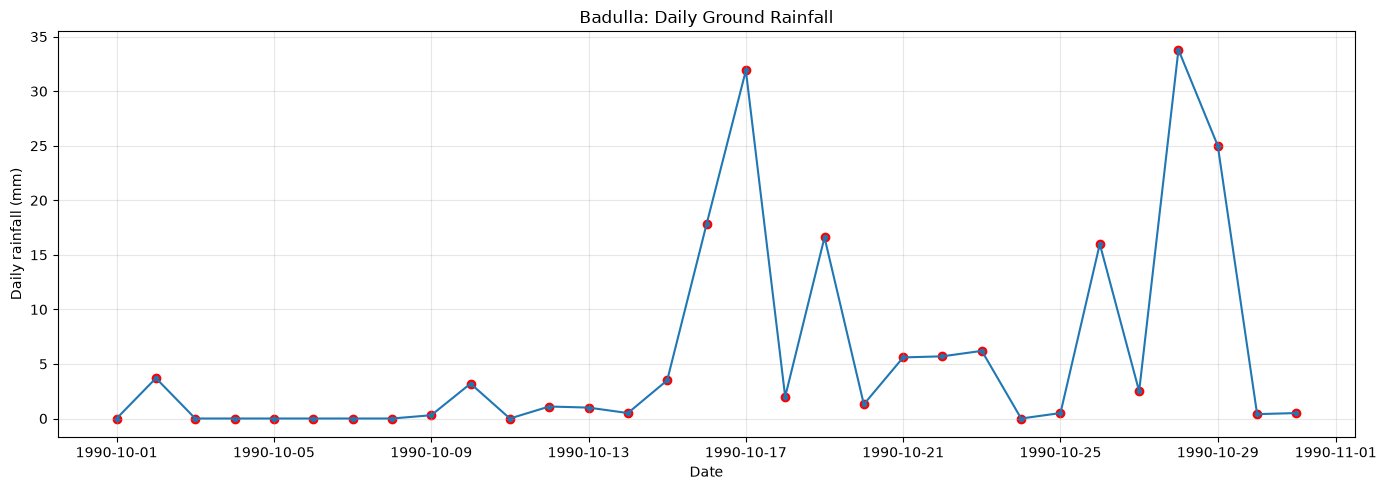

In [26]:
#Test three rainfall plots
#Daily rainfall for Badulla in October 1990:
plot_ground_rainfall("Badulla", "1990-10-01", "1990-10-31", "daily")


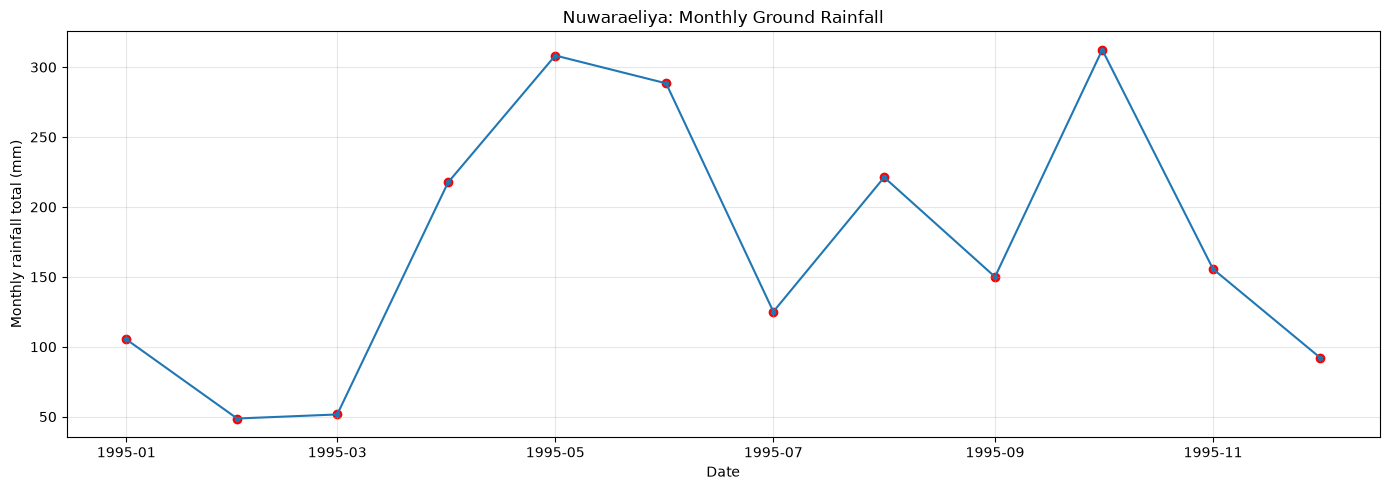

In [28]:
#Monthly rainfall for Nuwara Eliya in 1995
plot_ground_rainfall("Nuwaraeliya", "1995-01-01", "1995-12-31", "monthly")

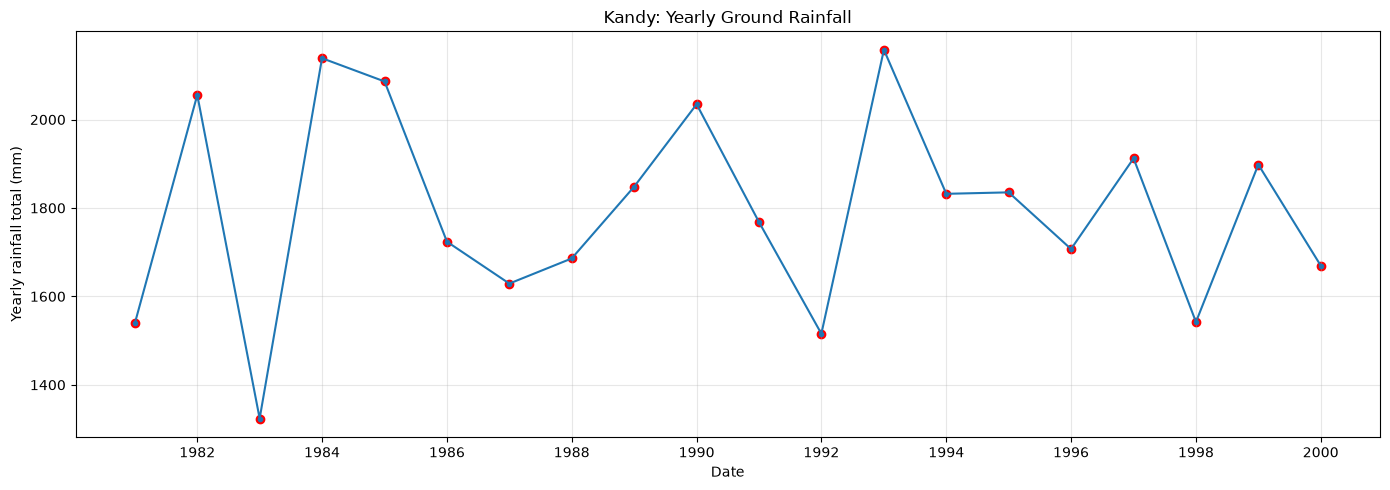

In [30]:
#Yearly rainfall for Kandy across the full period
plot_ground_rainfall("Kandy", "1981-01-01", "2000-12-31", "yearly")

#Check data completeness
#a monthly or yearly sum can be misleading when some days are missing.
def check_monthly_completeness(station):

    data = ground[ground["Station"] == station].copy()
    data = data.set_index("Date").sort_index()

    monthly = data["Rainfall_mm"].resample("MS").agg(["sum", "count"])
    monthly["Expected_Days"] = monthly.index.days_in_month

    monthly["Completeness"] = (monthly["count"] / monthly["Expected_Days"])
    return monthly

In [43]:
def check_monthly_completeness(station): #second method wouldnt like  this wouldny remove one les than 98%

    data = ground[ground["Station"] == station].copy()
    data = data.set_index("Date").sort_index()

    monthly = data["Rainfall_mm"].resample("MS").agg(["sum", "count"])
    monthly["Expected_Days"] = monthly.index.days_in_month
    monthly["Completeness"] = (monthly["count"] / monthly["Expected_Days"])
    monthly["Missing_Days"] = ( monthly["Expected_Days"] - monthly["count"])
    monthly["Complete"] = (monthly["Completeness"] == 1.0)

    return monthly

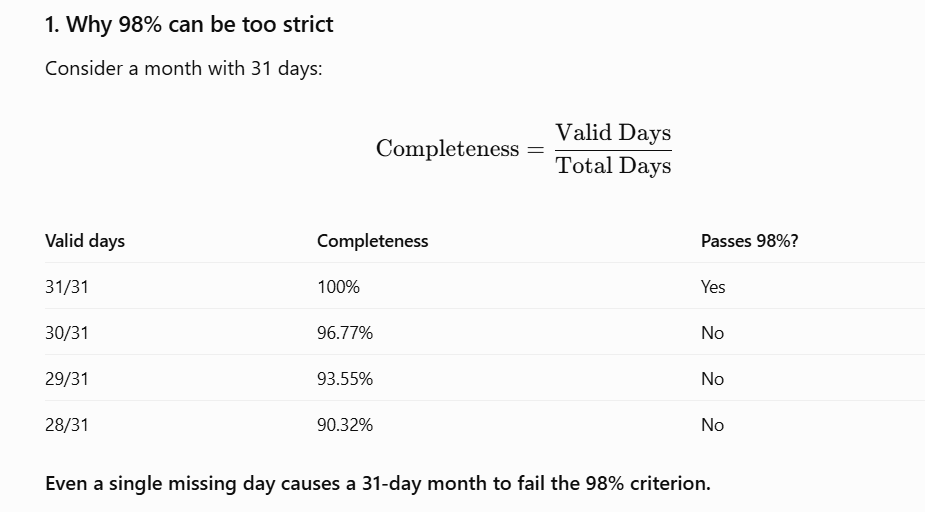

In [41]:
monthly_check = check_monthly_completeness("Badulla")

display(monthly_check.head(12))
print("Months below 98% completeness:",(monthly_check["Completeness"] < 0.98).sum())

,sum,count,Expected_Days,Completeness,Missing_Days,Complete
Date,,,,,,
1981-01-01,74.8,31,31,1.0,0,True
1981-02-01,110.0,28,28,1.0,0,True
1981-03-01,70.2,31,31,1.0,0,True
1981-04-01,175.2,30,30,1.0,0,True
1981-05-01,102.3,31,31,1.0,0,True
1981-06-01,11.5,30,30,1.0,0,True
1981-07-01,187.9,31,31,1.0,0,True
1981-08-01,28.1,31,31,1.0,0,True
1981-09-01,148.4,30,30,1.0,0,True


Months below 98% completeness: 3


In [45]:
#find the non complete month
incomplete_months = monthly_check[ monthly_check["Completeness"] < 0.98]
display(incomplete_months)

,sum,count,Expected_Days,Completeness,Missing_Days,Complete
Date,,,,,,
1988-07-01,51.9,29,31,0.935484,2,False
1989-07-01,216.7,29,31,0.935484,2,False
1997-01-01,4.9,30,31,0.967742,1,False


In [47]:
#find exacts missing dates
missing_badulla = ground[
    (ground["Station"] == "Badulla") &
    (ground["Rainfall_mm"].isna())
]

display(
    missing_badulla[
        ["Date", "Original_Value", "QC_Flag"]
    ]
)

,Date,Original_Value,QC_Flag
2766,1988-07-29,-9.9M,Missing
2767,1988-07-30,-9.9M,Missing
3129,1989-07-27,-9.9M,Missing
3130,1989-07-28,-9.9M,Missing
5846,1997-01-03,-9.9M,Missing


In [51]:
#To check Overall completness as abv
print("Total months:", len(monthly_check))
print("Fully complete months:",
      monthly_check["Complete"].sum())

print("Months below 98%:",
      (monthly_check["Completeness"] < 0.98).sum())


Total months: 240
Fully complete months: 237
Months below 98%: 3


In [53]:
#Keep missing observations without deleting months
monthly_check["Rainfall_Observed_mm"] = monthly_check["sum"]

monthly_check["Data_Status"] = np.where(
    monthly_check["Missing_Days"] == 0,
    "Complete",
    "Partial"
)

display(
    monthly_check[
        ["Rainfall_Observed_mm",
         "Missing_Days",
         "Completeness",
         "Data_Status"]
    ].tail(12)
)

,Rainfall_Observed_mm,Missing_Days,Completeness,Data_Status
Date,,,,
2000-01-01,178.3,0,1.0,Complete
2000-02-01,223.3,0,1.0,Complete
2000-03-01,59.3,0,1.0,Complete
2000-04-01,46.2,0,1.0,Complete
2000-05-01,62.3,0,1.0,Complete
2000-06-01,24.3,0,1.0,Complete
2000-07-01,17.9,0,1.0,Complete
2000-08-01,111.6,0,1.0,Complete
2000-09-01,229.6,0,1.0,Complete


In [55]:
#Compare rainfall between stations
def compare_stations(stations, start_date, end_date):
    data = ground[ ground["Station"].isin(stations)].copy()
    data = data[data["Date"].between( pd.Timestamp(start_date),pd.Timestamp(end_date))]
    fig, ax = plt.subplots(figsize=(14, 5))

    for station in stations:
        station_data = (data[data["Station"] == station].set_index("Date").sort_index())
        # Monthly observed totals
        monthly = station_data["Rainfall_mm"].resample("MS").sum(min_count=1)
        ax.plot( monthly.index, monthly.values, marker="o", markersize=3, label=station
        )

    ax.set_title("Monthly Ground Rainfall Comparison")
    ax.set_xlabel("Date")
    ax.set_ylabel("Observed monthly rainfall (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

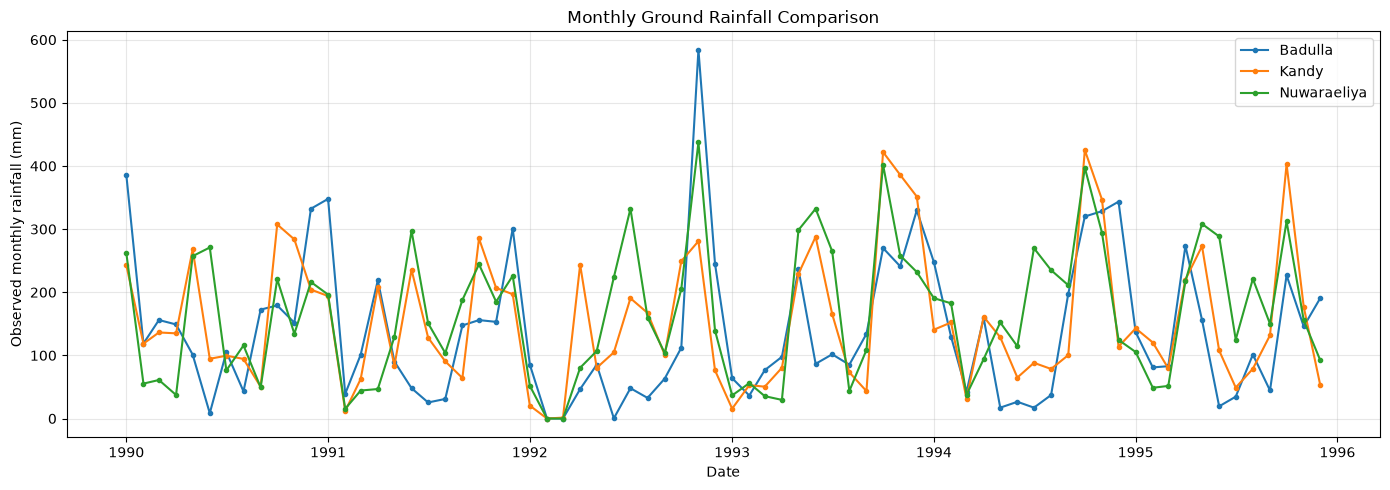

In [57]:
compare_stations(["Badulla", "Kandy", "Nuwaraeliya"],"1990-01-01","1995-12-31")


### Step 3.6.1 — What is seasonal climatology?

Instead of plotting every month from 1981–2000, we'll calculate the average rainfall for each calendar month over those 20 years.

For example:

$$
\overline{R}_{Jan} = \frac{R_{Jan,1981} + R_{Jan,1982} + \cdots + R_{Jan,2000}}{20}
$$

We'll calculate this separately for all six stations.

The resulting graph will have only 12 points per station, making seasonal patterns easier to identify.


In [64]:
def calculate_monthly_climatology(station):

    data = ground[ground["Station"] == station].copy()
    data = data.set_index("Date").sort_index()

    # Monthly rainfall totals and number of valid days
    monthly = data["Rainfall_mm"].resample("MS").agg(["sum", "count"])
    monthly["Expected_Days"] = monthly.index.days_in_month

    # Keep all 240 months, but mark incomplete totals
    monthly["Complete"] = (monthly["count"] == monthly["Expected_Days"])
    # Monthly rainfall totals from complete months only
    monthly["Rainfall_Total"] = monthly["sum"].where(monthly["Complete"])

    monthly["Month"] = monthly.index.month

    climatology = monthly.groupby("Month").agg(
        Mean_Rainfall=("Rainfall_Total", "mean"),
        Std_Rainfall=("Rainfall_Total", "std"),
        Years_Used=("Rainfall_Total", "count")
    )

    return climatology

In [66]:
badulla_climatology = calculate_monthly_climatology("Badulla")

display(badulla_climatology.round(2))

,Mean_Rainfall,Std_Rainfall,Years_Used
Month,,,
1,206.08,161.89,19
2,92.56,80.82,20
3,98.12,75.46,20
4,159.92,81.15,20
5,104.86,71.15,20
6,32.02,33.49,20
7,66.46,48.02,18
8,75.98,53.56,20
9,138.45,66.64,20


In [68]:
#Plotting seasonal rainfall patterens
def plot_monthly_climatology(stations):

    fig, ax = plt.subplots(figsize=(12, 5))

    month_names = [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]

    for station in stations:

        climatology = calculate_monthly_climatology(station)

        ax.plot(range(1, 13),climatology["Mean_Rainfall"],marker="o",linewidth=2,label=station )

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)

    ax.set_title("Monthly Rainfall Climatology (1981–2000)")
    ax.set_xlabel("Month")
    ax.set_ylabel("Mean monthly rainfall (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

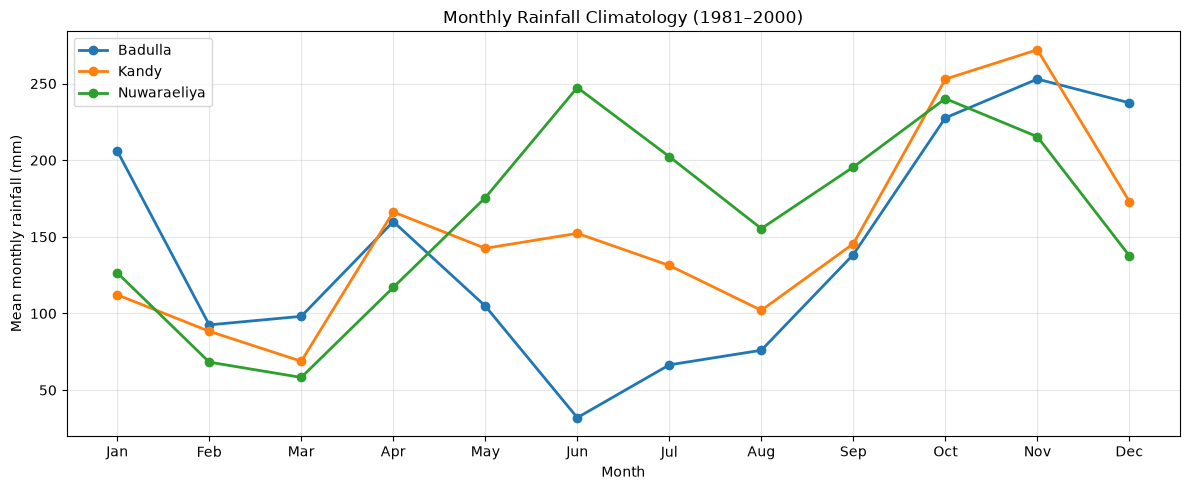

In [70]:
#compare hill country stations
plot_monthly_climatology(["Badulla", "Kandy", "Nuwaraeliya"])

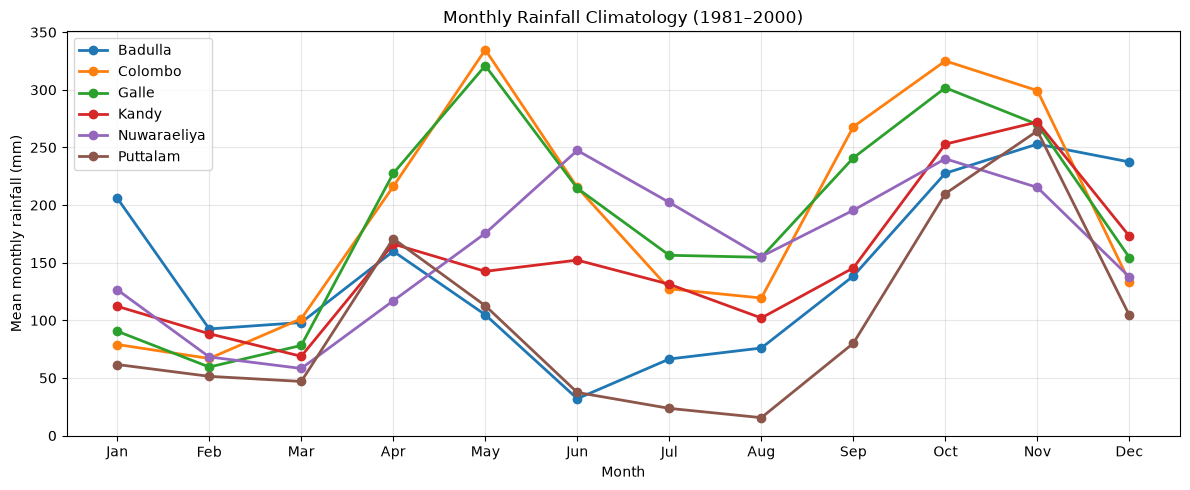

In [72]:
#compare all 6 steations
plot_monthly_climatology( ["Badulla","Colombo","Galle","Kandy","Nuwaraeliya","Puttalam" ])

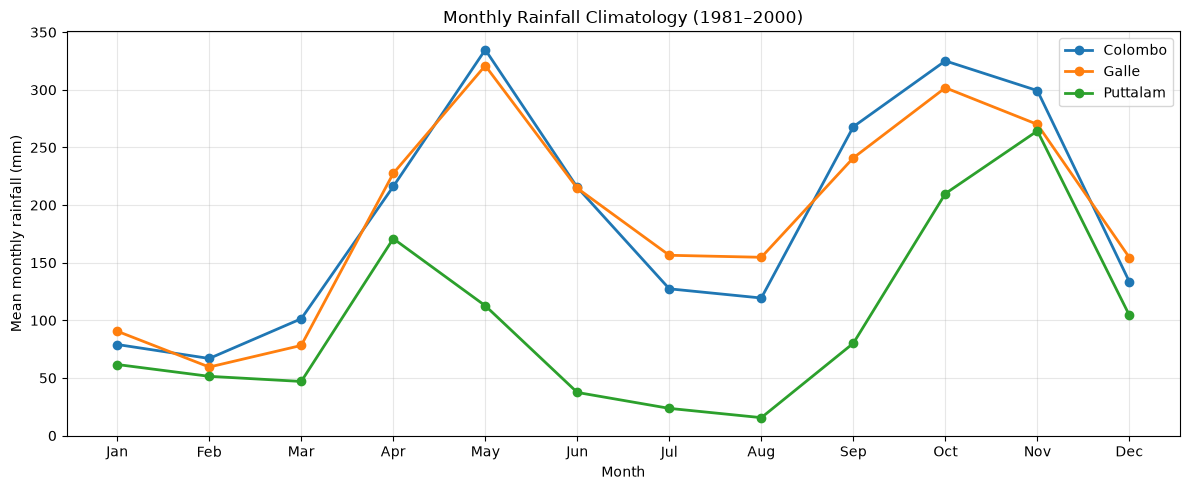

In [76]:
#Plot coastel cities
plot_monthly_climatology( ["Colombo","Galle","Puttalam" ])

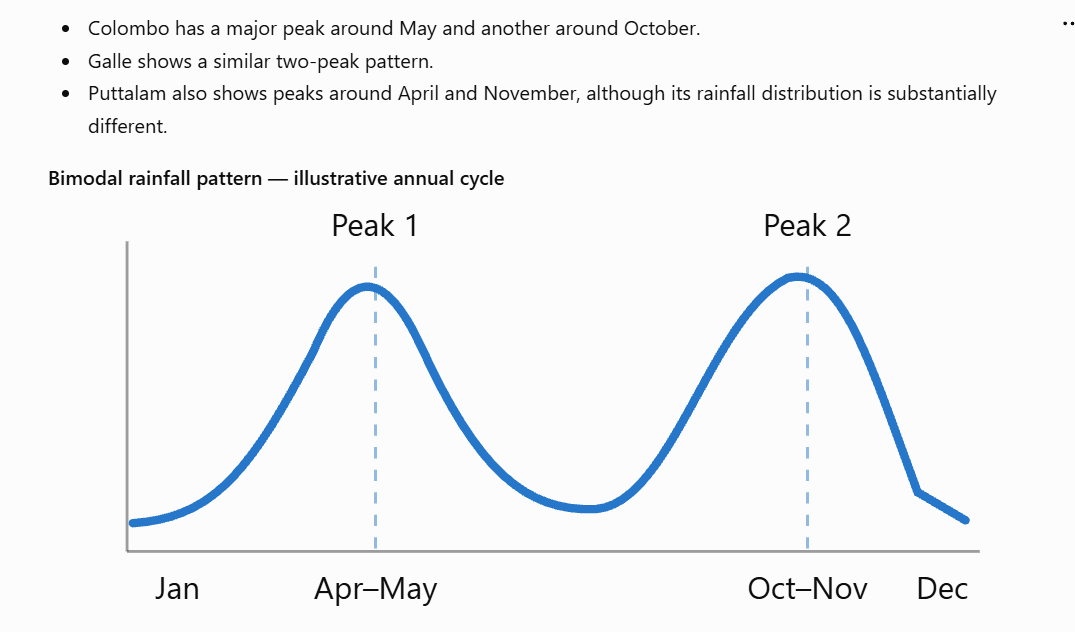

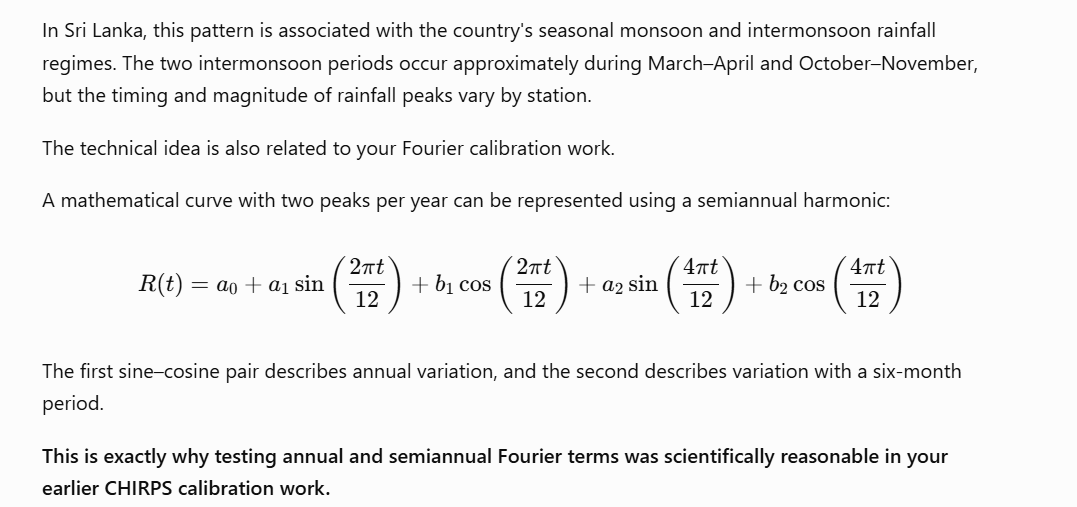

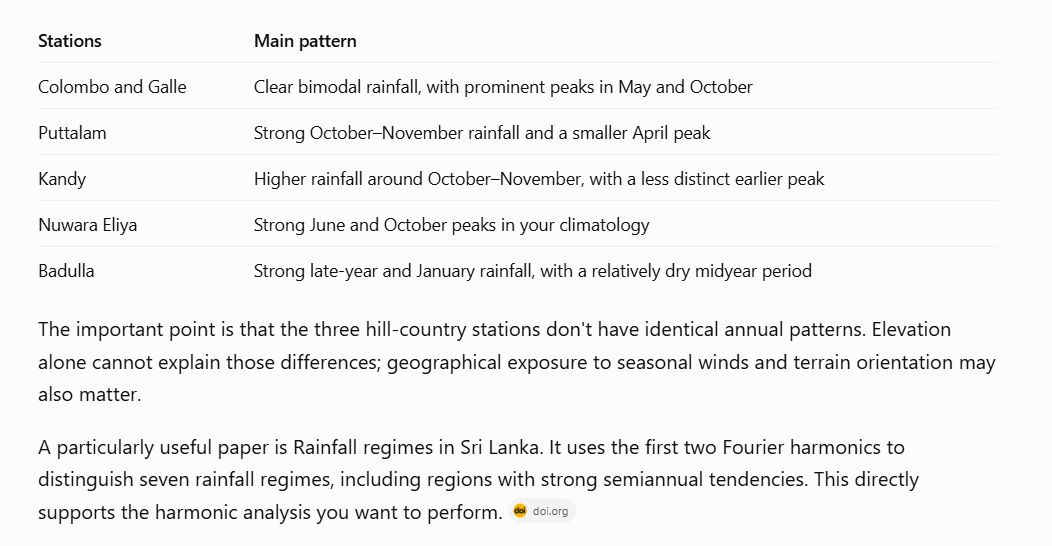


## Step 3.7 — Fourier Harmonic Analysis

We will use your existing monthly climatology to determine whether each station exhibits predominantly annual or semiannual rainfall variation.

We'll do this in the same notebook, directly after Step 3.6.

### Step 3.7.1 — Understand what we're fitting

The mathematical model is:

$$
R(t) = a_0 + a_1 \sin\left(\frac{2\pi t}{12}\right) + b_1 \cos\left(\frac{2\pi t}{12}\right) + a_2 \sin\left(\frac{4\pi t}{12}\right) + b_2 \cos\left(\frac{4\pi t}{12}\right)
$$

The first harmonic has a period of 12 months, while the second has a period of six months.

We'll use linear least squares to estimate the five coefficients from the 12 monthly climatology values.


In [82]:
def fit_fourier_climatology(station):

    climatology = calculate_monthly_climatology(station)

    t = climatology.index.to_numpy()
    y = climatology["Mean_Rainfall"].to_numpy()

    # Fourier design matrix
    X = np.column_stack([
        np.ones(len(t)),
        np.sin(2 * np.pi * t / 12),
        np.cos(2 * np.pi * t / 12),
        np.sin(4 * np.pi * t / 12),
        np.cos(4 * np.pi * t / 12)
    ])

    coefficients, *_ = np.linalg.lstsq(X, y, rcond=None) #finding optimal coefficents using least square fit regression

    fitted = X @ coefficients #by matrix multiplication it fill fit 

    # Annual and semiannual harmonic amplitudes
    A1 = np.sqrt(coefficients[1]**2 + coefficients[2]**2) #A1-amplitude of the anual harmoic = sqrt(a1^2+b1^2)
    A2 = np.sqrt(coefficients[3]**2 + coefficients[4]**2)#A2-amplitude of senu anula harmonic 

    rmse = np.sqrt(np.mean((y - fitted)**2))
    ss_res = np.sum((y - fitted)**2)
    ss_tot = np.sum((y - np.mean(y))**2)

    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return {
        "Station": station,
        "Months": t,
        "Observed": y,
        "Fitted": fitted,
        "Coefficients": coefficients,
        "Annual_Amplitude": A1,
        "Semiannual_Amplitude": A2,
        "RMSE": rmse,
        "R2": r2
    }

In [84]:
#Check for colombo
colombo_fit = fit_fourier_climatology("Colombo")

print("Annual amplitude:",round(colombo_fit["Annual_Amplitude"], 2))
print("Semiannual amplitude:", round(colombo_fit["Semiannual_Amplitude"], 2))

print("RMSE:", round(colombo_fit["RMSE"], 2))
print("R²:", round(colombo_fit["R2"], 3))

Annual amplitude: 56.22
Semiannual amplitude: 113.13
RMSE: 29.22
R²: 0.903


In [86]:
#Plot the observed and fitted climatology
def plot_fourier_fit(station):
    result = fit_fourier_climatology(station)
    plt.figure(figsize=(11, 5))
    plt.plot(result["Months"],result["Observed"],"o-",label="Observed climatology")
    plt.plot(result["Months"],result["Fitted"],"s--",label="Fourier fitted")
    plt.xticks(
        range(1, 13),
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )

    plt.xlabel("Month")
    plt.ylabel("Mean monthly rainfall (mm)")
    plt.title(f"{station}: Fourier Harmonic Analysis")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

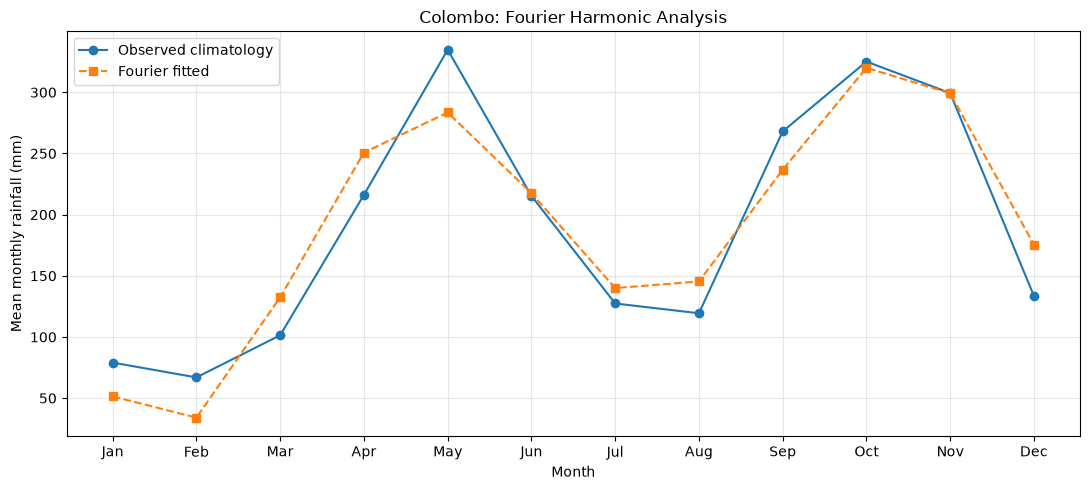

In [90]:
plot_fourier_fit("Colombo")

In [92]:
#check for galle
colombo_fit = fit_fourier_climatology("Galle")

print("Annual amplitude:",round(colombo_fit["Annual_Amplitude"], 2))
print("Semiannual amplitude:", round(colombo_fit["Semiannual_Amplitude"], 2))

print("RMSE:", round(colombo_fit["RMSE"], 2))
print("R²:", round(colombo_fit["R2"], 3))

Annual amplitude: 60.09
Semiannual amplitude: 96.5
RMSE: 22.67
R²: 0.926


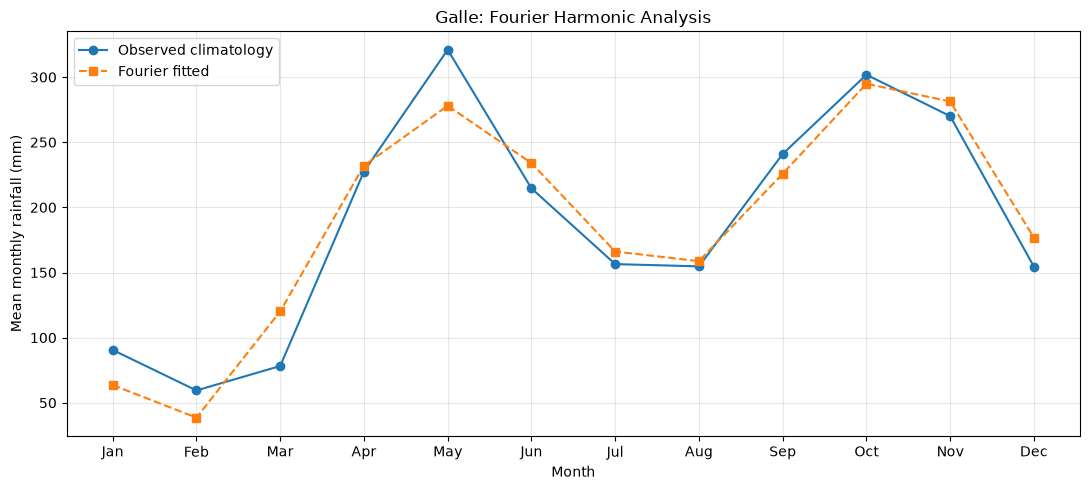

In [94]:
plot_fourier_fit("Galle")

In [96]:
#check for Putthalam
colombo_fit = fit_fourier_climatology("Puttalam")

print("Annual amplitude:",round(colombo_fit["Annual_Amplitude"], 2))
print("Semiannual amplitude:", round(colombo_fit["Semiannual_Amplitude"], 2))

print("RMSE:", round(colombo_fit["RMSE"], 2))
print("R²:", round(colombo_fit["R2"], 3))

Annual amplitude: 47.37
Semiannual amplitude: 87.49
RMSE: 27.07
R²: 0.871


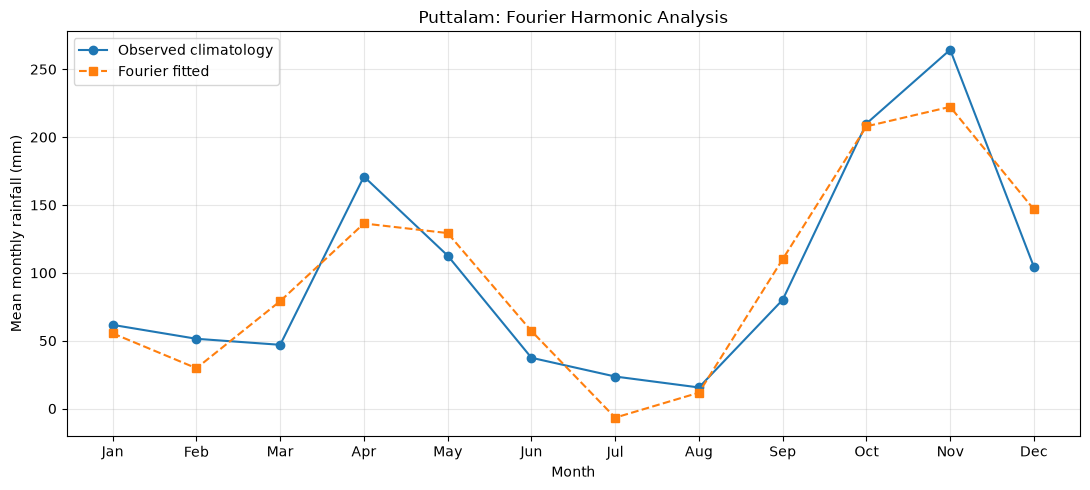

In [98]:
plot_fourier_fit("Puttalam")


Notice whether the fitted curve captures Colombo's two rainfall peaks in approximately May and October.

This is a descriptive fit to climatological averages, not an independent prediction test. A high $R^2$ tells us how well the harmonics describe the 12-month seasonal pattern, not how accurately they predict daily rainfall.


In [101]:
#Create a summary for all six stations
results = []

for station in sorted(ground["Station"].unique()):

    fit = fit_fourier_climatology(station)

    results.append({
        "Station": station,
        "Annual_Amplitude": fit["Annual_Amplitude"],
        "Semiannual_Amplitude": fit["Semiannual_Amplitude"],
        "Amplitude_Ratio": (
            fit["Semiannual_Amplitude"] /
            fit["Annual_Amplitude"]
            if fit["Annual_Amplitude"] > 0 else np.nan
        ),
        "RMSE": fit["RMSE"],
        "R2": fit["R2"]
    })

fourier_summary = pd.DataFrame(results)

display(fourier_summary.round(3))

,Station,Annual_Amplitude,Semiannual_Amplitude,Amplitude_Ratio,RMSE,R2
0,Badulla,84.104,45.443,0.540,22.843,0.898
1,Colombo,56.220,113.131,2.012,29.224,0.903
2,Galle,60.094,96.501,1.606,22.668,0.926
3,Kandy,47.140,61.956,1.314,19.300,0.891
4,Nuwaraeliya,66.124,43.768,0.662,20.272,0.884
5,Puttalam,47.370,87.491,1.847,27.074,0.871



### Step 3.8.1 — Plot rainfall variability with error bars

Your Fourier analysis showed the *average* seasonal rainfall pattern. But rainfall varies from year to year.

For example, Colombo may receive around 330 mm of rainfall in May on average, but individual years can receive considerably more or less.

We can visualize that variability using standard deviation.

The vertical error bars show **±1 standard deviation** across years, not measurement uncertainty or a confidence interval.

Large bars indicate that rainfall for that calendar month differs substantially from year to year.


In [112]:
def plot_rainfall_variability(station):

    climatology = calculate_monthly_climatology(station)
    months = np.arange(1, 13)
    plt.figure(figsize=(12, 5))
    plt.scatter(months,climatology["Mean_Rainfall"], color='red')
    plt.errorbar(
        months,
        climatology["Mean_Rainfall"],
        yerr=climatology["Std_Rainfall"],
        fmt="o-",
        capsize=4,
        label=station
    )

    plt.xticks(
        months,
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )

    plt.title(f"{station}: Monthly Rainfall Variability")
    plt.xlabel("Month")
    plt.ylabel("Monthly rainfall (mm)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

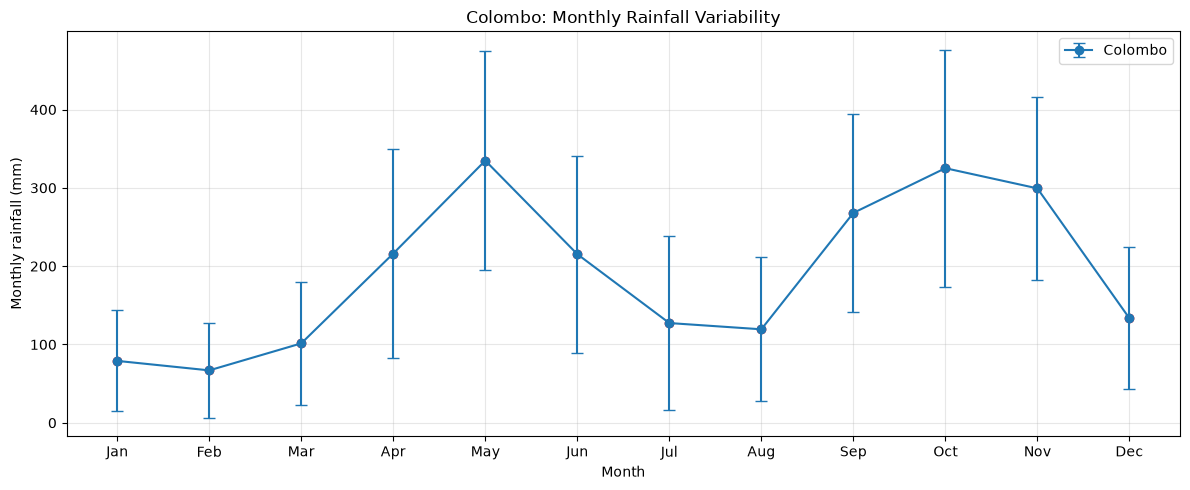

In [114]:
plot_rainfall_variability("Colombo")


### Step 3.8.2 — Plot cumulative rainfall

Next, we'll calculate cumulative rainfall for any station and selected period.

Because you want to preserve missing observations, we'll distinguish the cumulative total of *observed rainfall* from a complete cumulative record.


In [118]:
def plot_cumulative_rainfall(station, start_date, end_date):

    data = ground[
        (ground["Station"] == station) &
        (ground["Date"].between(
            pd.Timestamp(start_date),
            pd.Timestamp(end_date)
        ))
    ].copy().sort_values("Date")

    if data.empty:
        print("No data for this selection.")
        return

    # Cumulative sum of available observations
    data["Cumulative_mm"] = (data["Rainfall_mm"].fillna(0).cumsum())
    # Hide cumulative values at missing dates
    data.loc[ data["Rainfall_mm"].isna(), "Cumulative_mm"] = np.nan
    plt.figure(figsize=(13, 5))
    plt.plot(data["Date"],data["Cumulative_mm"], label="Accumulated observed rainfall")

    plt.title(f"{station}: Cumulative Observed Rainfall")
    plt.xlabel("Date")
    plt.ylabel("Accumulated rainfall (mm)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

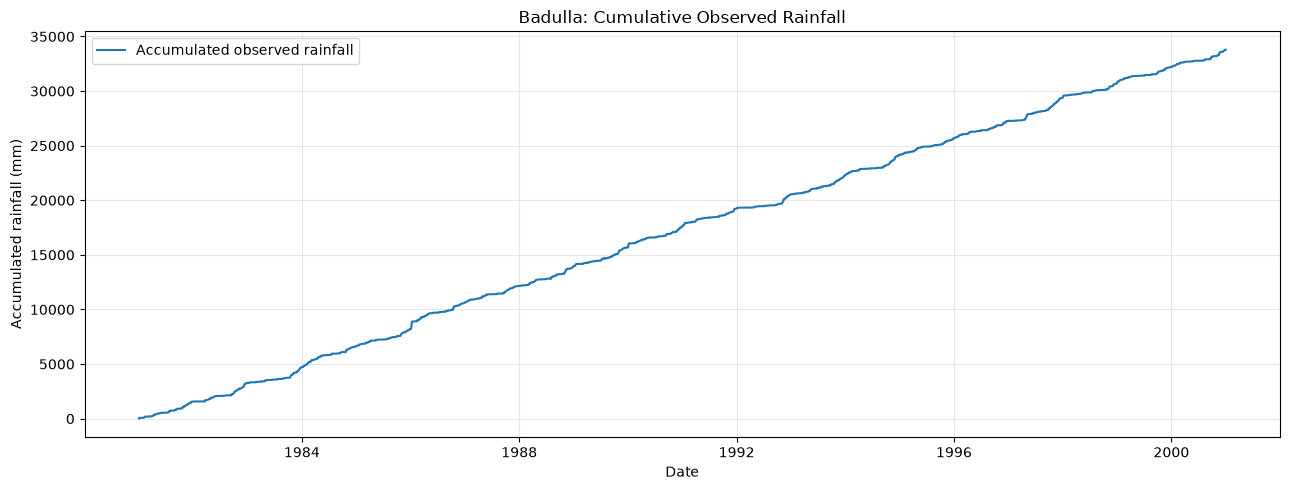

In [120]:
plot_cumulative_rainfall("Badulla","1981-01-01","2000-12-31")

Compare annual rainfall totals, This helps us assess long-term variability without assuming that annual rainfall is perfectly predictable.

In [125]:
def plot_annual_rainfall(station):

    data = ground[
        ground["Station"] == station
    ].copy().set_index("Date").sort_index()

    yearly = data["Rainfall_mm"].resample("YS").agg(["sum", "count"])
    yearly["Expected_Days"] = np.where( yearly.index.is_leap_year, 366, 365 )
    yearly["Complete"] = (yearly["count"] == yearly["Expected_Days"])

    fig, ax = plt.subplots(figsize=(12, 5))
    years = yearly.index.year
    ax.plot( years, yearly["sum"], marker="o", label="Observed annual total" )
    partial = yearly[~yearly["Complete"]]
    ax.scatter(partial.index.year, partial["sum"],marker="x", s=85, label="Incomplete year")

    ax.set_title(f"{station}: Annual Observed Rainfall")
    ax.set_xlabel("Year")
    ax.set_ylabel("Rainfall (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

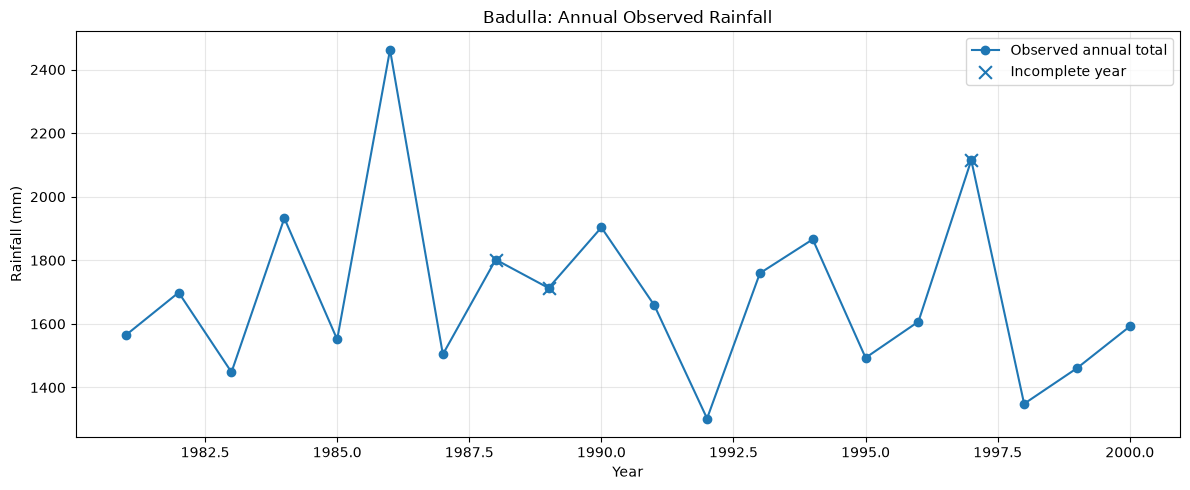

In [127]:
plot_annual_rainfall("Badulla")


## Step 3.9 — ENSO and Sri Lankan Rainfall

We'll continue working in `02_Ground_Rainfall_Analysis.ipynb`.

### Objective

Our aim is to compare **monthly rainfall anomalies** at our six rainfall stations against the historical **Niño 3.4 index** for the period **1981–2000**.

This will help us investigate whether changes in Sri Lankan rainfall are associated with the El Niño–Southern Oscillation (ENSO).

### Step 3.9.1 — Understanding ENSO

**ENSO (El Niño–Southern Oscillation)** is a natural climate phenomenon involving changes in sea surface temperatures and atmospheric circulation across the tropical Pacific Ocean.

ENSO has three main phases:

1. **El Niño:** Warmer-than-average sea surface temperatures in the central and eastern tropical Pacific.
2. **La Niña:** Cooler-than-average sea surface temperatures in the same region.
3. **ENSO-neutral:** Sea surface temperatures remain relatively close to their long-term average.

These changes influence atmospheric circulation and can affect rainfall patterns in different parts of the world, including Sri Lanka.

### Step 3.9.2 — What is the Niño 3.4 index?

The **Niño 3.4 index** measures sea surface temperature anomalies in the central equatorial Pacific Ocean, approximately between 5°N–5°S and 170°W–120°W.

It indicates whether Pacific Ocean temperatures are warmer or cooler than normal.

- **Positive Niño 3.4 values:** Warmer Pacific conditions associated with El Niño.
- **Negative Niño 3.4 values:** Cooler Pacific conditions associated with La Niña.
- **Values near zero:** Approximately ENSO-neutral conditions.

For formal ENSO event classification, sustained temperature anomalies and a specified averaging period are normally required. A single monthly value does not necessarily indicate an established ENSO event.

### Step 3.9.3 — What is a rainfall anomaly?

A **rainfall anomaly** measures how much rainfall in a particular month differs from the long-term average rainfall for that calendar month.

The mathematical expression is:

$$
\boxed{\text{Rainfall Anomaly}_{y,m} = R_{y,m} - \overline{R}_m}
$$

**Where:**

- $R_{y,m}$ = Observed rainfall (mm) in year $y$ and month $m$.
- $\overline{R}_m$ = Long-term average rainfall (mm) for calendar month $m$, calculated over 1981–2000.
- $y$ = Year of observation.
- $m$ = Calendar month (January to December).

**Interpretation:**

- **Positive anomaly:** The month received more rainfall than its usual monthly average.
- **Negative anomaly:** The month received less rainfall than its usual monthly average.
- **Zero anomaly:** The rainfall equalled its usual monthly average.

**Example:**

Suppose Colombo's average rainfall in May is 330 mm.

If the observed rainfall in May 1995 was 400 mm:

$$
\text{Rainfall Anomaly} = 400 - 330 = +70\text{ mm}
$$

This means May 1995 was **70 mm wetter than the long-term May average**.

If rainfall was instead 250 mm:

$$
\text{Rainfall Anomaly} = 250 - 330 = -80\text{ mm}
$$

This means the month was **80 mm drier than normal**.

### Step 3.9.4 — Why do we calculate rainfall anomalies?

Rainfall naturally changes throughout the year because of seasonal patterns, including monsoons.

For example, Colombo generally receives more rainfall during certain monsoon and inter-monsoon months.

Comparing raw rainfall against ENSO may therefore mix the effects of the normal seasonal cycle with unusual rainfall variations.

By subtracting the long-term average for each calendar month, we remove the **average seasonal cycle**.

This allows us to investigate whether unusually wet or dry months are associated with ENSO conditions.

### Step 3.9.5 — How does ENSO affect Sri Lankan rainfall?

Published Sri Lankan research has identified seasonally varying relationships between ENSO and rainfall.

During **El Niño**, the average relationships reported include:

| Period | General rainfall association |
|--------|------------------------------|
| October–December | Wetter-than-average conditions |
| January–March | Drier-than-average conditions |
| July–August | Drier-than-average conditions |

**Important:** These are statistical tendencies, not guaranteed outcomes.

The strength and direction of the ENSO–rainfall relationship can differ between stations, seasons, and geographical regions, especially in mountainous areas.

La Niña may produce contrasting rainfall tendencies, but its effects are not necessarily exact opposites of El Niño.

### Step 3.9.6 — What will we investigate?

Using rainfall observations from our six stations and the Niño 3.4 index, we will:

1. Calculate monthly rainfall anomalies for each station during 1981–2000.
2. Compare rainfall anomalies with the corresponding monthly Niño 3.4 values.
3. Investigate whether positive or negative Niño 3.4 values are associated with wetter or drier conditions.
4. Examine whether the relationship changes between seasons.
5. Compare relationships across the six stations.

We can use time-series plots, scatter plots, and correlation coefficients to examine these relationships.

**Important considerations:**

- Correlation does not establish causation.
- ENSO effects may appear after a time delay (lag).
- Missing rainfall observations should remain missing rather than being replaced with zero.
- Correlations calculated across all months may hide important seasonal differences.
- The 1981–2000 analysis covers only 20 years, so results should be interpreted cautiously.

**Expected outcome:**

This analysis will help us identify whether ENSO is statistically associated with rainfall variability at our six stations, and whether the relationships differ by season and location.


In [130]:
#calculate monrgly rainfall anonymally
def calculate_rainfall_anomalies(station):

    data = ground[
        ground["Station"] == station
    ].copy().set_index("Date").sort_index()

    monthly = data["Rainfall_mm"].resample("MS").agg(["sum", "count"])
    monthly["Expected_Days"] = monthly.index.days_in_month

    # Retain monthly records; avoid treating partial totals
    # as complete monthly rainfall
    monthly["Rainfall_Total"] = monthly["sum"].where(
        monthly["count"] == monthly["Expected_Days"]   #calculate monthly rainfall total 
    )

    monthly["Month"] = monthly.index.month
    climatology = monthly.groupby("Month")["Rainfall_Total"].transform("mean") #calculate long term abg from climatolgy 

    monthly["Anomaly_mm"] = (monthly["Rainfall_Total"] - climatology)
    return monthly

In [134]:
ENSO_DIR = PROJECT_DIR / "data" / "enso"

print("Available ENSO files:")
for file in ENSO_DIR.iterdir():
    print(file.name)

Available ENSO files:
nina34.anom.csv


In [136]:
#inspecting the downloaded file
ENSO_DIR = PROJECT_DIR / "data" / "enso"

enso_raw = pd.read_csv(ENSO_DIR / "nina34.anom.csv")

display(enso_raw.head())
print(enso_raw.columns)
print(enso_raw.tail())

,Date,Nino Anom 3.4 Index using NOAA OISST v2 from NCEI missing value -99.99 https://psl.noaa.gov/data/timeseries/month/
0,1948-01-01,-9999.0
1,1948-02-01,-9999.0
2,1948-03-01,-9999.0
3,1948-04-01,-9999.0
4,1948-05-01,-9999.0


Index(['Date', '   Nino Anom 3.4 Index  using NOAA OISST v2 from NCEI  missing value -99.99 https://psl.noaa.gov/data/timeseries/month/'], dtype='str')
           Date  \
559  1994-08-01   
560  1994-09-01   
561  1994-10-01   
562  1994-11-01   
563  1994-12-01   

        Nino Anom 3.4 Index  using NOAA OISST v2 from NCEI  missing value -99.99 https://psl.noaa.gov/data/timeseries/month/  
559                                            -9999.0                                                                        
560                                            -9999.0                                                                        
561                                            -9999.0                                                                        
562                                            -9999.0                                                                        
563                                            -9999.0                                            

In [138]:
#rename the two columns and identify missing values
enso = enso_raw.copy()
enso.columns = ["Date", "Nino34"]

enso["Date"] = pd.to_datetime(enso["Date"])
enso["Nino34"] = pd.to_numeric(
    enso["Nino34"], errors="coerce"
)

enso.loc[enso["Nino34"] <= -99, "Nino34"] = np.nan

print("First date:", enso["Date"].min())
print("Last date:", enso["Date"].max())
print("Last valid measurement:",
      enso.loc[enso["Nino34"].notna(), "Date"].max())

display(enso.tail())

First date: 1948-01-01 00:00:00
Last date: 1994-12-01 00:00:00
Last valid measurement: 1994-07-01 00:00:00


,Date,Nino34
559,1994-08-01,NaN
560,1994-09-01,NaN
561,1994-10-01,NaN
562,1994-11-01,NaN
563,1994-12-01,NaN


In [142]:
#Read the file - The NOAA file uses spaces rather than commas to separate its columns. It also has repeated ANOM column names, so we'll give them distinct names.
ENSO_DIR = PROJECT_DIR / "data" / "enso"

column_names = [
    "Year", "Month",
    "Nino12_SST", "Nino12_Anomaly",
    "Nino3_SST", "Nino3_Anomaly",
    "Nino4_SST", "Nino4_Anomaly",
    "Nino34_SST", "Nino34_Anomaly"
]

enso = pd.read_csv(
    ENSO_DIR / "NOAA_Nino_Indices.txt",
    sep=r"\s+",
    skiprows=1,
    names=column_names
)

display(enso.head())

,Year,Month,Nino12_SST,Nino12_Anomaly,Nino3_SST,Nino3_Anomaly,Nino4_SST,Nino4_Anomaly,Nino34_SST,Nino34_Anomaly
0,1950,1,23.01,-1.55,23.56,-2.10,26.94,-1.38,24.55,-1.99
1,1950,2,24.32,-1.78,24.89,-1.52,26.67,-1.53,25.06,-1.69
2,1950,3,25.11,-1.38,26.36,-0.84,26.52,-1.80,25.87,-1.42
3,1950,4,23.63,-1.90,26.44,-1.14,26.90,-1.73,26.28,-1.54
4,1950,5,22.68,-1.74,25.69,-1.57,27.73,-1.18,26.18,-1.75


In [144]:
#Prepare the 1981–2000 observations
enso["Date"] = pd.to_datetime(
    dict(year=enso["Year"], month=enso["Month"], day=1)
)

enso = enso[
    enso["Year"].between(1981, 2000)
].copy()

enso["Nino34_Anomaly"] = pd.to_numeric(
    enso["Nino34_Anomaly"],
    errors="coerce"
)

enso.loc[
    enso["Nino34_Anomaly"] <= -99,
    "Nino34_Anomaly"
] = np.nan

print("First date:", enso["Date"].min())
print("Last date:", enso["Date"].max())
print("Total months:", len(enso))
print("Missing values:", enso["Nino34_Anomaly"].isna().sum())

display(
    enso[["Date", "Nino34_Anomaly"]].head()
)

First date: 1981-01-01 00:00:00
Last date: 2000-12-01 00:00:00
Total months: 240
Missing values: 0


,Date,Nino34_Anomaly
372,1981-01-01,-0.36
373,1981-02-01,-0.64
374,1981-03-01,-0.64
375,1981-04-01,-0.53
376,1981-05-01,-0.57


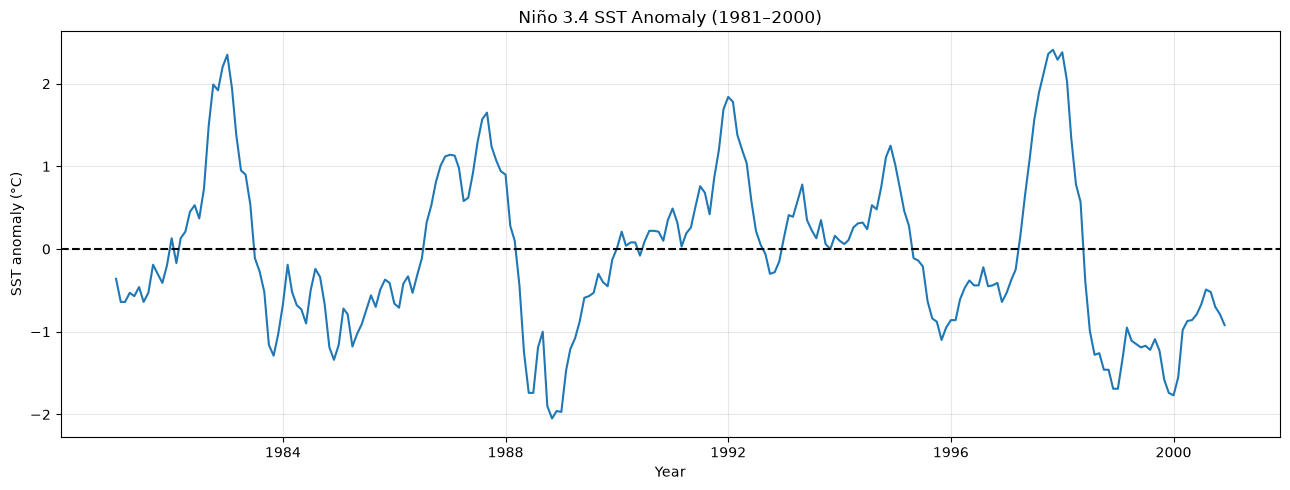

In [146]:
#Plot the ENSO index
plt.figure(figsize=(13, 5))

plt.plot(enso["Date"],enso["Nino34_Anomaly"],linewidth=1.5)
plt.axhline(0, color="black", linestyle="--")
plt.title("Niño 3.4 SST Anomaly (1981–2000)")
plt.xlabel("Year")
plt.ylabel("SST anomaly (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Positive values represent warmer-than-average Niño 3.4 sea-surface temperatures; negative values represent cooler-than-average conditions. Individual monthly anomaly values alone do not establish formal El Niño or La Niña episode classifications.

In [149]:
#Combine ENSO and Badulla rainfall
# Get Badulla monthly rainfall anomalies
badulla_anomalies = calculate_rainfall_anomalies("Badulla")

# Convert monthly date index into a column
badulla_monthly = badulla_anomalies.reset_index()

# Select ENSO data
enso_monthly = enso[["Date", "Nino34_Anomaly"]].copy()

# Join using matching calendar months
badulla_enso = pd.merge(
    badulla_monthly,
    enso_monthly,
    on="Date",
    how="left",
    validate="one_to_one"
)

print("Total months:", len(badulla_enso))
print("Valid paired months:",
      badulla_enso[["Anomaly_mm", "Nino34_Anomaly"]]
      .dropna().shape[0])

display(
    badulla_enso[
        ["Date", "Rainfall_Total", "Anomaly_mm", "Nino34_Anomaly"]
    ].head()
)

Total months: 240
Valid paired months: 237


,Date,Rainfall_Total,Anomaly_mm,Nino34_Anomaly
0,1981-01-01,74.8,-131.284211,-0.36
1,1981-02-01,110.0,17.445000,-0.64
2,1981-03-01,70.2,-27.925000,-0.64
3,1981-04-01,175.2,15.280000,-0.53
4,1981-05-01,102.3,-2.560000,-0.57


You should have 240 calendar months, with 237 usable rainfall months if your previous Badulla completeness check remains unchanged and the ENSO values are all available.

Remember: the three incomplete months are still present. Their rainfall anomalies are simply undefined.

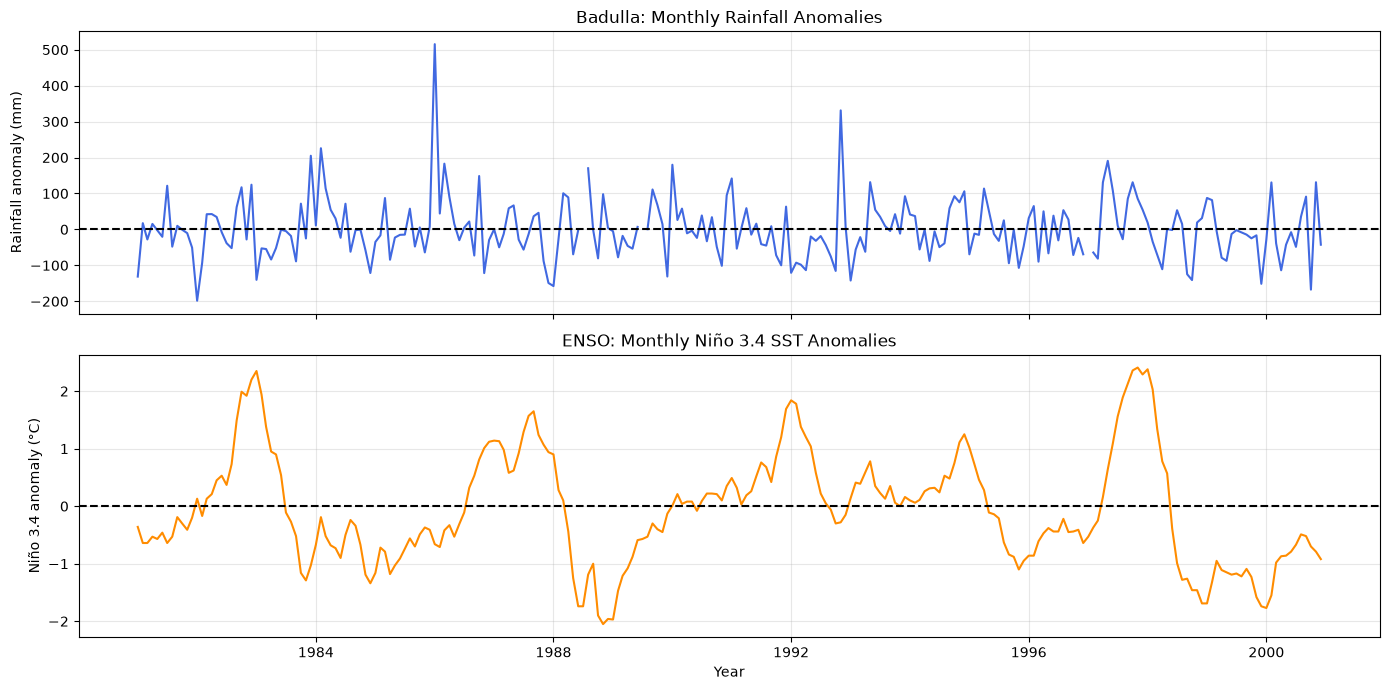

In [152]:
#Plot both anomaly series
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(badulla_enso["Date"],badulla_enso["Anomaly_mm"],color="royalblue")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Rainfall anomaly (mm)")
axes[0].set_title("Badulla: Monthly Rainfall Anomalies")

axes[1].plot(badulla_enso["Date"],badulla_enso["Nino34_Anomaly"],color="darkorange")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_ylabel("Niño 3.4 anomaly (°C)")
axes[1].set_xlabel("Year")
axes[1].set_title("ENSO: Monthly Niño 3.4 SST Anomalies")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

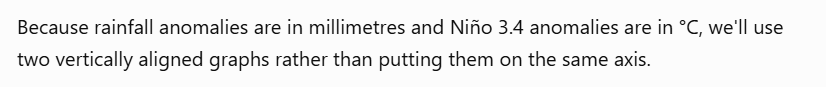

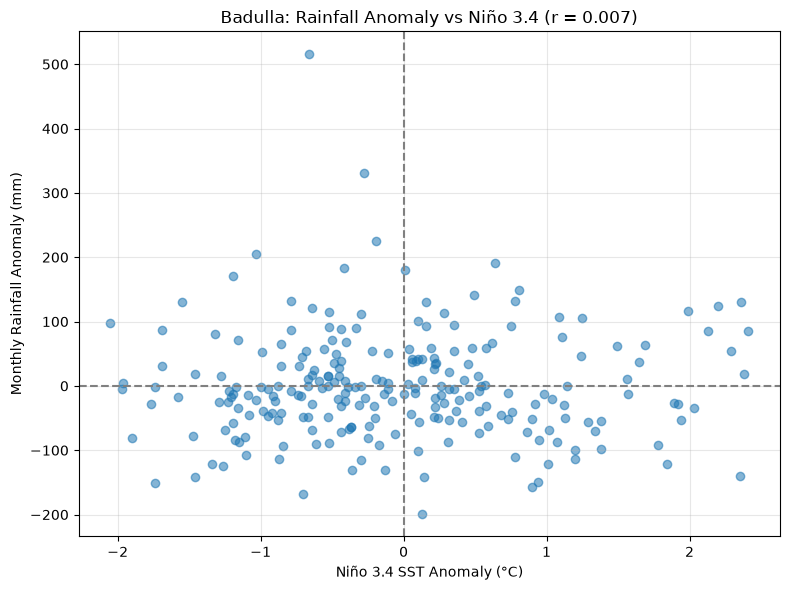

Pearson correlation: 0.007


In [155]:
#Scatter plot and Pearson correlation
paired_enso = badulla_enso[ ["Anomaly_mm", "Nino34_Anomaly"]].dropna()
correlation = paired_enso[ "Anomaly_mm"].corr(paired_enso["Nino34_Anomaly"])

plt.figure(figsize=(8, 6))

plt.scatter(paired_enso["Nino34_Anomaly"],paired_enso["Anomaly_mm"],alpha=0.55)
plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.title(f"Badulla: Rainfall Anomaly vs Niño 3.4 (r = {correlation:.3f})")
plt.xlabel("Niño 3.4 SST Anomaly (°C)")
plt.ylabel("Monthly Rainfall Anomaly (mm)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Pearson correlation:", round(correlation, 3))

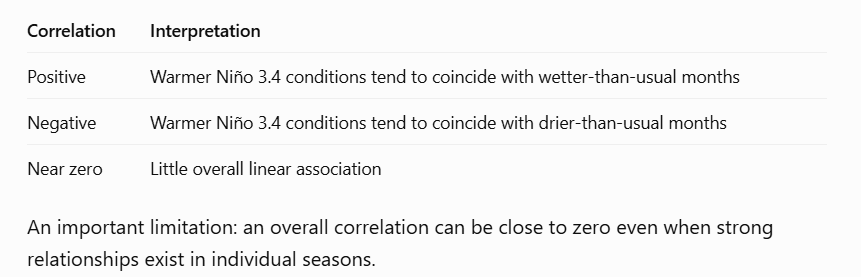

In [158]:
#Compare seasons seperatly
badulla_enso["Month"] = badulla_enso["Date"].dt.month

seasons = {
    "Jan-Mar": [1, 2, 3],
    "Apr-Jun": [4, 5, 6],
    "Jul-Aug": [7, 8],
    "Sep-Dec": [9, 10, 11, 12],
    "Oct-Dec": [10, 11, 12]
}

season_results = []

for season, months in seasons.items():

    subset = badulla_enso[
        badulla_enso["Month"].isin(months)
    ][["Anomaly_mm", "Nino34_Anomaly"]].dropna()

    r = subset["Anomaly_mm"].corr(
        subset["Nino34_Anomaly"]
    )

    season_results.append({
        "Season": season,
        "Paired_Months": len(subset),
        "Correlation": r
    })

season_summary = pd.DataFrame(season_results)

display(season_summary.round(3))

,Season,Paired_Months,Correlation
0,Jan-Mar,59,-0.319
1,Apr-Jun,60,0.215
2,Jul-Aug,38,-0.419
3,Sep-Dec,80,0.289
4,Oct-Dec,60,0.255


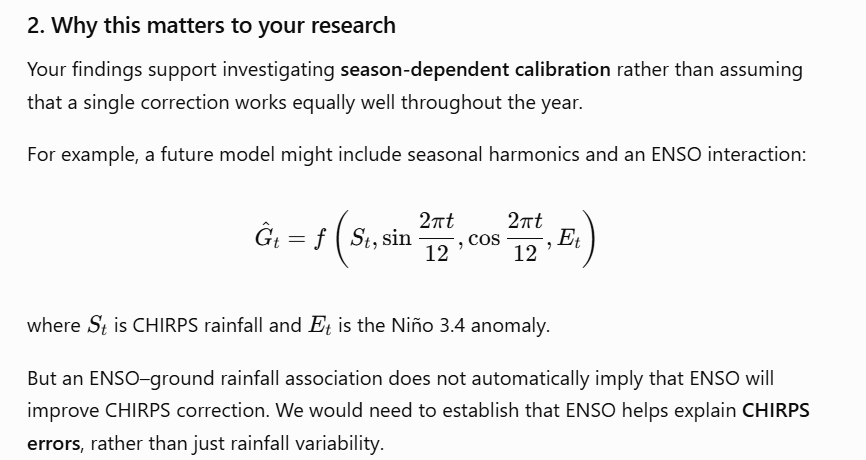

In [161]:
season_summary.to_csv(PROJECT_DIR / "results" / "Badulla_ENSO_Seasonal_Correlation.csv",index=False)
fourier_summary.to_csv( PROJECT_DIR / "results" / "Ground_Fourier_Summary.csv", index=False)